In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tqdm
import copy

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

from src.trees.fastodt import FastODT

from src.ensemble_methods.elasticGBDT import ElasticGBDT
from src.ensemble_methods.LearnNSE import LearnNSE  

In [3]:
import numpy as np

# --- PARAMETERS ---
n_batches               = 50
n_samples_per_batch     = 30
noise_std               = 0.5
concept_drift_strength  = 20.2   # 0=no drift; 1=exactly to end; >1=overshoot

# Linear models for start & end concepts
START_W, END_W = np.array([1.0, 1.0]), np.array([2.0, -1.0])
START_B, END_B = 0.0, 0.5

# --- 1) Drift generators with unbounded strength ---

def generate_sudden_drift(t, n_batches, n_samples, noise_std, strength):
    """
    Sudden step at midpoint: if t <= mid   ⇒ alpha=0,
                          else            ⇒ alpha=1,
    then w = START_W + strength*(END_W-START_W).
    """
    X = np.random.rand(n_samples, 2)
    mid = n_batches // 2
    alpha = 1.0 if t > mid else 0.0
    w = START_W + strength * alpha * (END_W - START_W)
    b = START_B + strength * alpha * (END_B - START_B)
    y = X.dot(w) + b + np.random.randn(n_samples) * noise_std
    return X, y

def generate_incremental_drift(t, n_batches, n_samples, noise_std, strength):
    """
    Linear ramp: base_frac = t/(n_batches-1),
    then alpha = base_frac * strength (no clipping).
    """
    X = np.random.rand(n_samples, 2)
    base_frac = t / (n_batches - 1)
    alpha = base_frac * strength
    w = START_W + alpha * (END_W - START_W)
    b = START_B + alpha * (END_B - START_B)
    y = X.dot(w) + b + np.random.randn(n_samples) * noise_std
    return X, y

def generate_gradual_drift(t, n_batches, n_samples, noise_std, strength):
    """
    Smooth (cosine) schedule: 
      eased = 0.5*(1 - cos(pi * t/(n_batches-1)))
    then alpha = eased * strength (no clipping).
    """
    X = np.random.rand(n_samples, 2)
    eased = 0.5 * (1 - np.cos(np.pi * t / (n_batches - 1)))
    alpha = eased * strength
    w = START_W + alpha * (END_W - START_W)
    b = START_B + alpha * (END_B - START_B)
    y = X.dot(w) + b + np.random.randn(n_samples) * noise_std
    return X, y

# --- 2) Drift schedule & selector ---

# Phases across 30 batches (indices 0–29)
schedule = [
    (generate_incremental_drift,  0,  10),
    (generate_sudden_drift,      11,  19),
    (generate_gradual_drift,     20,  29),
]

def drift_fn(batch_idx, n_samples):
    for fn, start, end in schedule:
        if start <= batch_idx <= end:
            return fn(batch_idx, n_batches, n_samples, noise_std, concept_drift_strength)
    # Fallback (shouldn't happen)
    return generate_incremental_drift(batch_idx, n_batches, n_samples, noise_std, concept_drift_strength)


Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[BatchErrorHistory] insufficient history (1), skipping dynamic prune.
[BatchErrorHistory] insufficient history (1), skipping dynamic prune.
[BatchErrorHistory] insufficient history (1), skipping dynamic prune.
[BatchErrorHistory] insufficient history (1), skipping dynamic prune.
[BatchErrorHistory] insufficient history (2), skipping dynamic prune.
[BatchErrorHistory] insufficient history (2), skipping dynamic prune.
[BatchErrorHistory] insufficient history (2), skipping dynamic prune.
[BatchErrorHistory] insufficient history (2), skipping dynamic prune.
[BatchErrorHistory] insufficient history (3), skipping dynamic prune.
[B

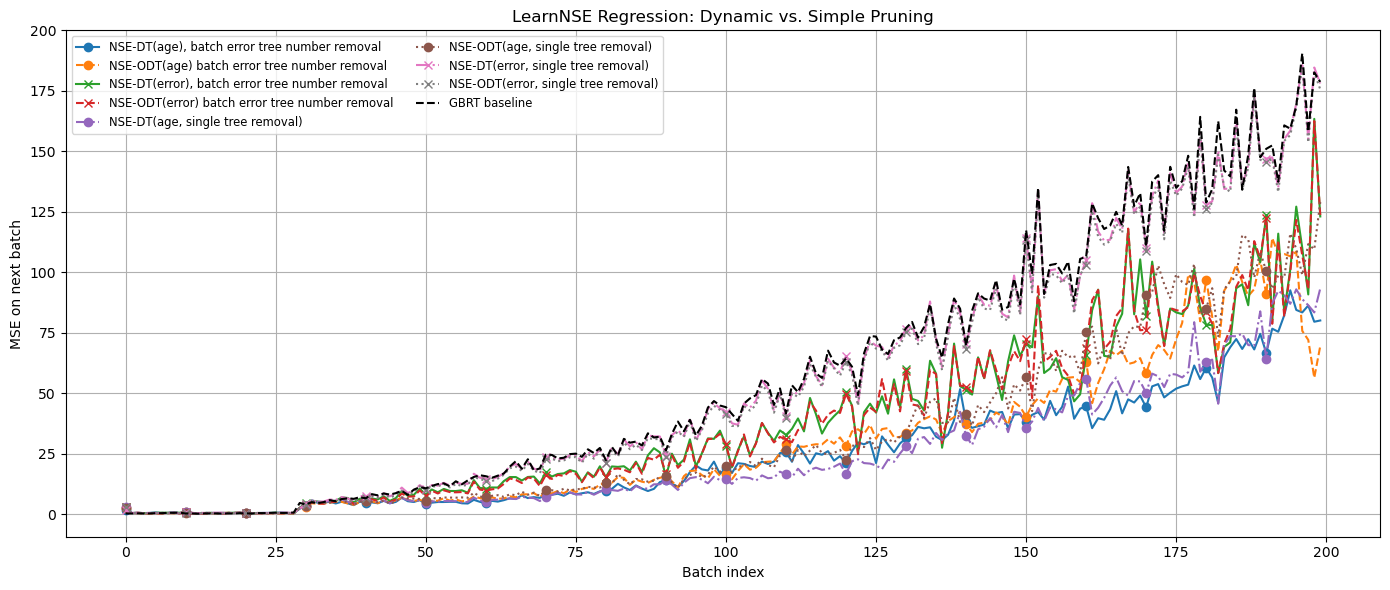

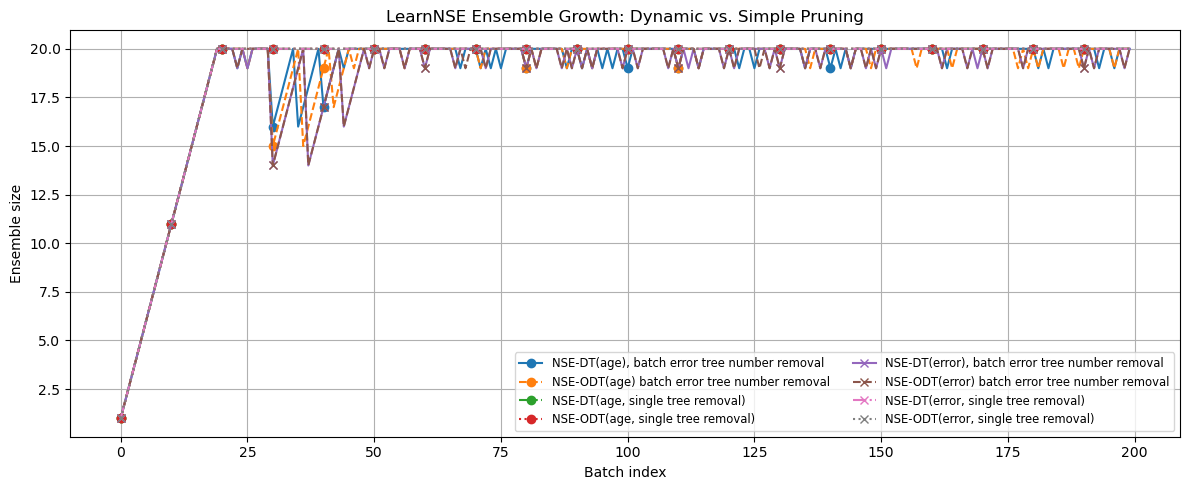

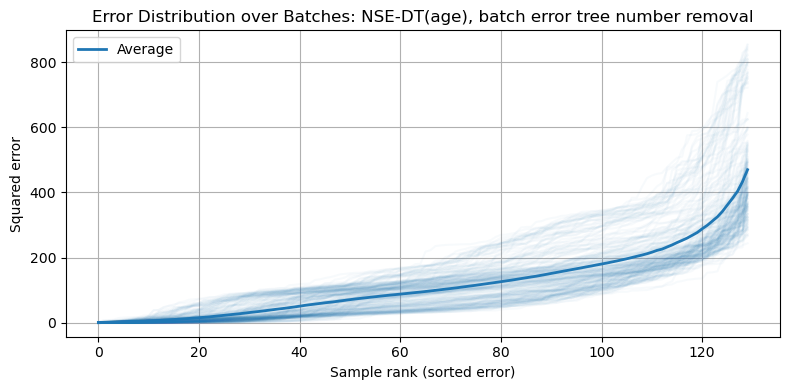

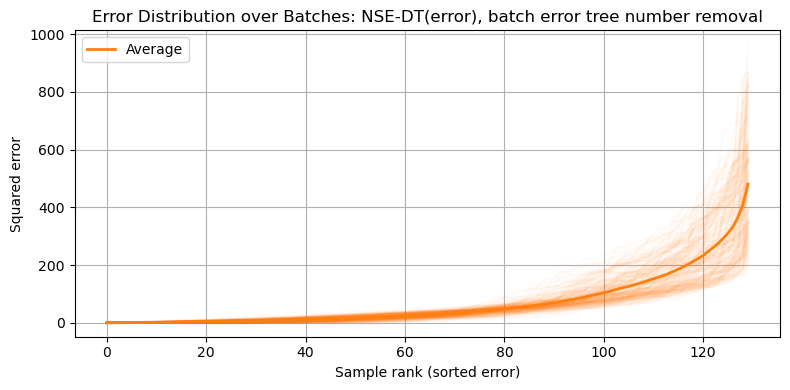

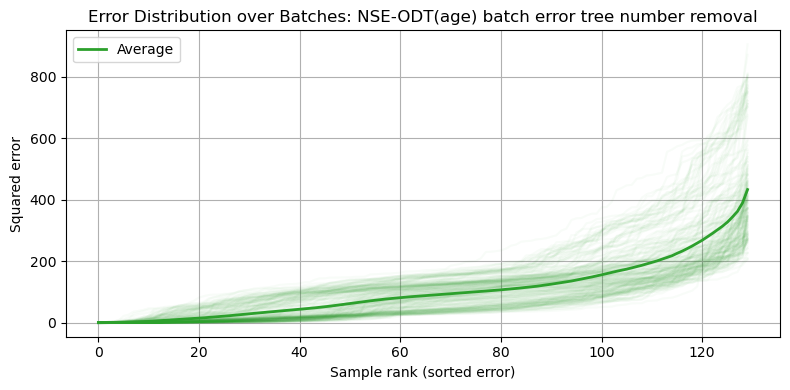

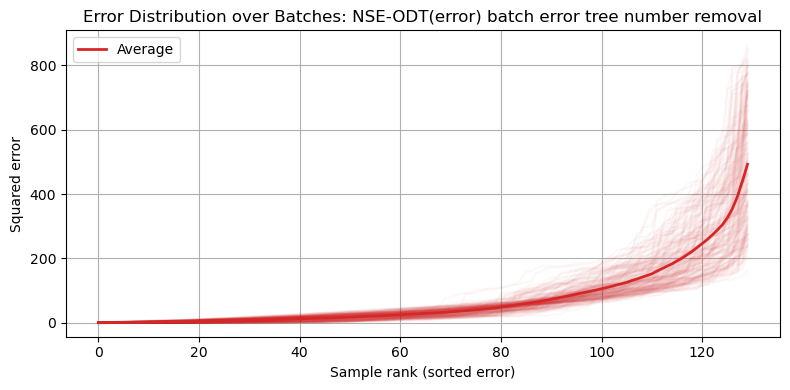

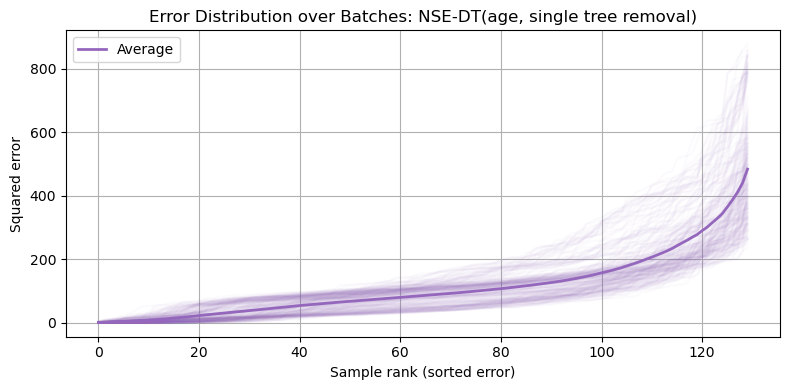

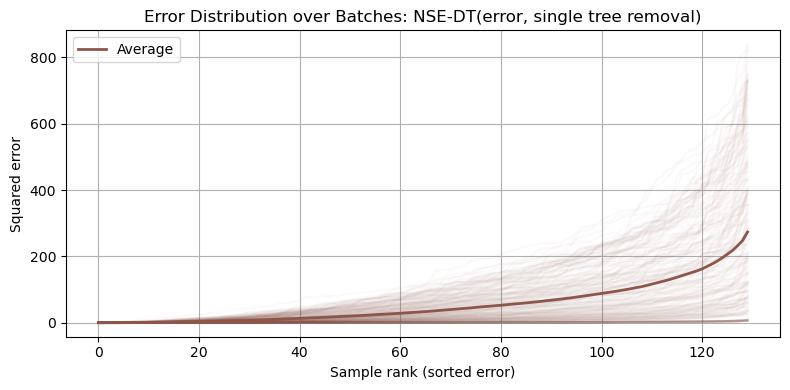

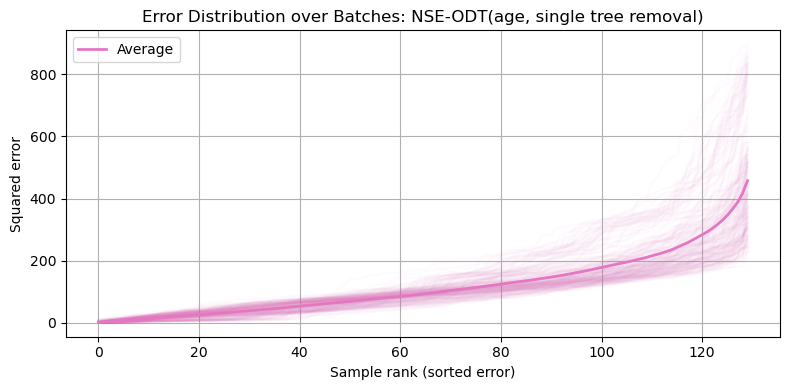

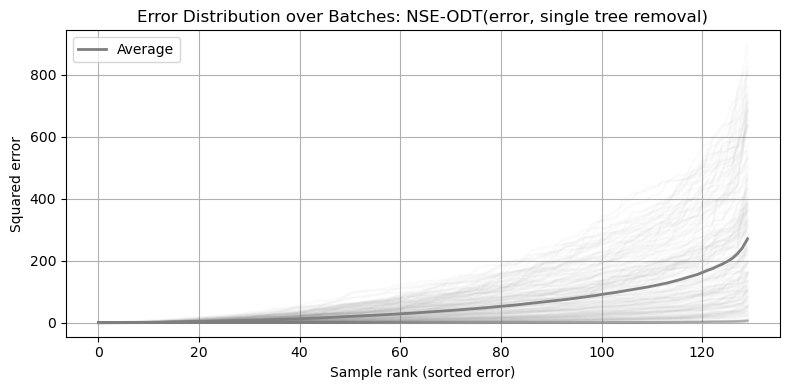

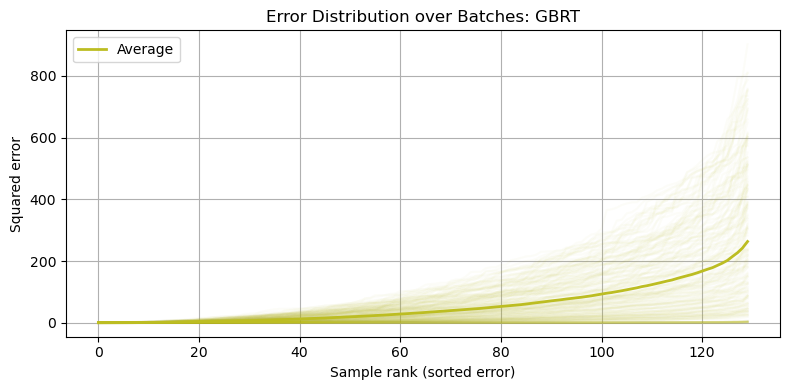

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
import itertools


# --- Parameters ---
ensemble_size = 20
n_batches = 200
n_samples_per_batch = 130

# --- Drift function (already defined) ---
# def drift_fn(t, n_samples_per_batch): ...

# --- 1) Instantiate NSE variants ---

pruning_types = ['age', 'error']
names_dt  = [f"NSE-DT({p}), batch error tree number removal"           for p in pruning_types]
names_odt = [f"NSE-ODT({p}) batch error tree number removal"          for p in pruning_types]
names_dt_nc  = [f"NSE-DT({p}, single tree removal)"     for p in pruning_types]
names_odt_nc = [f"NSE-ODT({p}, single tree removal)"    for p in pruning_types]

# With dynamic removal_count_calculation = True
nse_dt    = [
    LearnNSE(base_classifier=DecisionTreeRegressor(random_state=0),
             ensemble_size=ensemble_size,
             pruning_type=p,
             removal_count_calculation=True,
             alpha_multiplier=0.8, beta_multiplier=0.55,
             gamma_multiplier=0.3, fixed_multiplier=1.5, baseline=1.2)
    for p in pruning_types
]
nse_odt   = [
    LearnNSE(base_classifier=FastODT(),
             ensemble_size=ensemble_size,
             pruning_type=p,
             removal_count_calculation=True,
             alpha_multiplier=0.8, beta_multiplier=0.55,
             gamma_multiplier=0.3, fixed_multiplier=1.5, baseline=1.2)
    for p in pruning_types
]

# With removal_count_calculation = False (only simple age/error prune)
nse_dt_nc    = [
    LearnNSE(base_classifier=DecisionTreeRegressor(random_state=0),
             ensemble_size=ensemble_size,
             pruning_type=p,
             removal_count_calculation=False)
    for p in pruning_types
]
nse_odt_nc   = [
    LearnNSE(base_classifier=FastODT(),
             ensemble_size=ensemble_size,
             pruning_type=p,
             removal_count_calculation=False)
    for p in pruning_types
]

# Static GBRT baseline
gb_baseline = GradientBoostingRegressor(n_estimators=ensemble_size, random_state=0)
X0, y0 = drift_fn(0, n_samples_per_batch)
gb_baseline.fit(X0, y0)

all_models = nse_dt + nse_odt + nse_dt_nc + nse_odt_nc + [gb_baseline]
all_names  = names_dt + names_odt + names_dt_nc + names_odt_nc + ['GBRT']

# --- 2) Prepare tracking lists ---
n_variants = len(pruning_types)
mse_dt      = [ [] for _ in pruning_types ]
mse_odt     = [ [] for _ in pruning_types ]
mse_dt_nc   = [ [] for _ in pruning_types ]
mse_odt_nc  = [ [] for _ in pruning_types ]
mse_gb      = []

size_dt     = [ [] for _ in pruning_types ]
size_odt    = [ [] for _ in pruning_types ]
size_dt_nc  = [ [] for _ in pruning_types ]
size_odt_nc = [ [] for _ in pruning_types ]

# --- 3) Online evaluation ---
for t in range(n_batches):
    X_train, y_train = drift_fn(t, n_samples_per_batch)

    # update all NSE ensembles
    for ens in (nse_dt + nse_odt + nse_dt_nc + nse_odt_nc):
        ens.fit(X_train, y_train)

    # evaluate on next batch
    X_test, y_test = drift_fn(t+1, n_samples_per_batch)

    for i, ens in enumerate(nse_dt):
        mse_dt[i].append(mean_squared_error(y_test, ens.predict(X_test)))
        size_dt[i].append(len(ens.models))
    for i, ens in enumerate(nse_odt):
        mse_odt[i].append(mean_squared_error(y_test, ens.predict(X_test)))
        size_odt[i].append(len(ens.models))
    for i, ens in enumerate(nse_dt_nc):
        mse_dt_nc[i].append(mean_squared_error(y_test, ens.predict(X_test)))
        size_dt_nc[i].append(len(ens.models))
    for i, ens in enumerate(nse_odt_nc):
        mse_odt_nc[i].append(mean_squared_error(y_test, ens.predict(X_test)))
        size_odt_nc[i].append(len(ens.models))

    mse_gb.append(mean_squared_error(y_test, gb_baseline.predict(X_test)))

# --- 4) Plot MSE over time ---
plt.figure(figsize=(14,6))
markers = ['o','x','s','d']
# dynamic NSE
for i, p in enumerate(pruning_types):
    plt.plot(mse_dt[i],   marker=markers[i], markevery=10, label=names_dt[i])
    plt.plot(mse_odt[i],  marker=markers[i], markevery=10, linestyle='--', label=names_odt[i])
# non-dynamic NSE
for i, p in enumerate(pruning_types):
    plt.plot(mse_dt_nc[i],   marker=markers[i], markevery=10, linestyle='-.', label=names_dt_nc[i])
    plt.plot(mse_odt_nc[i],  marker=markers[i], markevery=10, linestyle=':',  label=names_odt_nc[i])
# GBRT
plt.plot(mse_gb, '--', color='black', label='GBRT baseline')

plt.xlabel('Batch index')
plt.ylabel('MSE on next batch')
plt.title('LearnNSE Regression: Dynamic vs. Simple Pruning')
plt.legend(ncol=2, fontsize='small')
plt.grid(True)
plt.tight_layout()
plt.show()

# --- 5) Plot ensemble size over time ---
plt.figure(figsize=(12,5))
for i, p in enumerate(pruning_types):
    plt.plot(size_dt[i],    marker=markers[i], markevery=10, label=names_dt[i])
    plt.plot(size_odt[i],   marker=markers[i], markevery=10, linestyle='--', label=names_odt[i])
    plt.plot(size_dt_nc[i], marker=markers[i], markevery=10, linestyle='-.', label=names_dt_nc[i])
    plt.plot(size_odt_nc[i],marker=markers[i], markevery=10, linestyle=':',  label=names_odt_nc[i])

plt.xlabel('Batch index')
plt.ylabel('Ensemble size')
plt.title('LearnNSE Ensemble Growth: Dynamic vs. Simple Pruning')
plt.legend(ncol=2, fontsize='small')
plt.grid(True)
plt.tight_layout()
plt.show()

# --- 6) Per-sample errors for each model ---
x_idx = np.arange(n_samples_per_batch)
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for model, name, color in zip(all_models, all_names, itertools.cycle(colors)):
    plt.figure(figsize=(8,4))
    all_sorted = []
    for t in range(n_batches):
        Xb, yb = drift_fn(t, n_samples_per_batch)
        errs = (model.predict(Xb) - yb)**2
        errs_sorted = np.sort(errs)
        all_sorted.append(errs_sorted)
        plt.plot(x_idx, errs_sorted, color=color, alpha=0.03)
    mean_sorted = np.mean(all_sorted, axis=0)
    plt.plot(x_idx, mean_sorted, color=color, label='Average', linewidth=2)
    plt.xlabel('Sample rank (sorted error)')
    plt.ylabel('Squared error')
    plt.title(f'Error Distribution over Batches: {name}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
